# 01 - Downloading and preparing raw data

## Business objective

This notebook creates the raw source dataset used across the credit-risk analytics workflow.
The main purpose is to fetch the public UCI dataset, validate the schema, and store a consistent raw file for downstream analysis.

## Scope

- Download the public credit card default dataset
- Store it in the project raw-data folder
- Keep a reproducible source-of-truth table for later notebooks


### Data source

The data comes from the UCI Machine Learning Repository and represents credit-card repayment behavior and default outcomes.


In [31]:
# Technical setup: define the workspace paths so the notebook runs from the repo root or from the notebooks folder.
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from ucimlrepo import fetch_ucirepo
from pathlib import Path
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)


RANDOM_STATE = 42


In [32]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
OUTPUT_PATH = PROJECT_ROOT / "data" / "outputs"
FIGURES_PATH = PROJECT_ROOT / "reports" / "figures"

for path in [
    RAW_PATH,
    PROCESSED_PATH,
    OUTPUT_PATH,
    FIGURES_PATH
]:
    path.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_PATH)
print("Processed data:", PROCESSED_PATH)
print("Outputs:", OUTPUT_PATH)

Project root: c:\GITHUB\analytics_platform
Raw data: c:\GITHUB\analytics_platform\data\raw
Processed data: c:\GITHUB\analytics_platform\data\processed
Outputs: c:\GITHUB\analytics_platform\data\outputs


In [33]:
dataset = fetch_ucirepo(id=350)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (30000, 23)
Target shape: (30000, 1)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679


,Y
0,1
1,1
2,0
3,0
4,0


In [34]:
print("Dataset metadata:")
display(dataset.metadata)

print("\nVariable information:")
display(dataset.variables)

Dataset metadata:


{'uci_id': 350,
 'name': 'Default of Credit Card Clients',
 'repository_url': 'https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients',
 'data_url': 'https://archive.ics.uci.edu/static/public/350/data.csv',
 'abstract': "This research aimed at the case of customers' default payments in Taiwan and compares the predictive accuracy of probability of default among six data mining methods.",
 'area': 'Business',
 'tasks': ['Classification'],
 'characteristics': ['Multivariate'],
 'num_instances': 30000,
 'num_features': 23,
 'feature_types': ['Integer', 'Real'],
 'demographics': ['Sex', 'Education Level', 'Marital Status', 'Age'],
 'target_col': ['Y'],
 'index_col': ['ID'],
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 2009,
 'last_updated': 'Fri Mar 29 2024',
 'dataset_doi': '10.24432/C55S3H',
 'creators': ['I-Cheng Yeh'],
 'intro_paper': {'ID': 365,
  'type': 'NATIVE',
  'title': 'The comparisons of data mining techniques for the


Variable information:


,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,NaN,NaN,None,no
1,X1,Feature,Integer,NaN,LIMIT_BAL,None,no
2,X2,Feature,Integer,Sex,SEX,None,no
3,X3,Feature,Integer,Education Level,EDUCATION,None,no
4,X4,Feature,Integer,Marital Status,MARRIAGE,None,no
5,X5,Feature,Integer,Age,AGE,None,no
6,X6,Feature,Integer,NaN,PAY_0,None,no
7,X7,Feature,Integer,NaN,PAY_2,None,no
8,X8,Feature,Integer,NaN,PAY_3,None,no
9,X9,Feature,Integer,NaN,PAY_4,None,no


In [35]:
column_mapping = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6"
}

X = X.rename(columns=column_mapping)

print("Renamed columns:")
print(X.columns.tolist())

display(X.head())

Renamed columns:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [36]:
target_name = y.columns[0]

df = pd.concat(
    [
        X.reset_index(drop=True),
        y.rename(
            columns={target_name: "DEFAULT"}
        ).reset_index(drop=True)
    ],
    axis=1
)

print("Final dataset shape:", df.shape)

display(df.head())

Final dataset shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [37]:
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("DATA_TYPE"))

print("\nDataset sample:")
display(df.head(10))

Number of records: 30000
Number of columns: 24

Column names:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT']

Data types:


,DATA_TYPE
LIMIT_BAL,int64
SEX,int64
EDUCATION,int64
MARRIAGE,int64
AGE,int64
PAY_0,int64
PAY_2,int64
PAY_3,int64
PAY_4,int64
PAY_5,int64



Dataset sample:


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0
5,50000,1,1,2,37,0,0,0,0,0,0,64400,57069,57608,19394,19619,20024,2500,1815,657,1000,1000,800,0
6,500000,1,1,2,29,0,0,0,0,0,0,367965,412023,445007,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
7,100000,2,2,2,23,0,-1,-1,0,0,-1,11876,380,601,221,-159,567,380,601,0,581,1687,1542,0
8,140000,2,3,1,28,0,0,2,0,0,0,11285,14096,12108,12211,11793,3719,3329,0,432,1000,1000,1000,0
9,20000,1,3,2,35,-2,-2,-2,-2,-1,-1,0,0,0,0,13007,13912,0,0,0,13007,1122,0,0


In [38]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


In [39]:
print("Target distribution:")

display(
    df["DEFAULT"]
    .value_counts(dropna=False)
    .to_frame("CLIENTS")
)

print("\nTarget percentage:")

display(
    df["DEFAULT"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("PERCENTAGE")
)

Target distribution:


,CLIENTS
DEFAULT,
0,23364
1,6636



Target percentage:


,PERCENTAGE
DEFAULT,
0,77.88
1,22.12


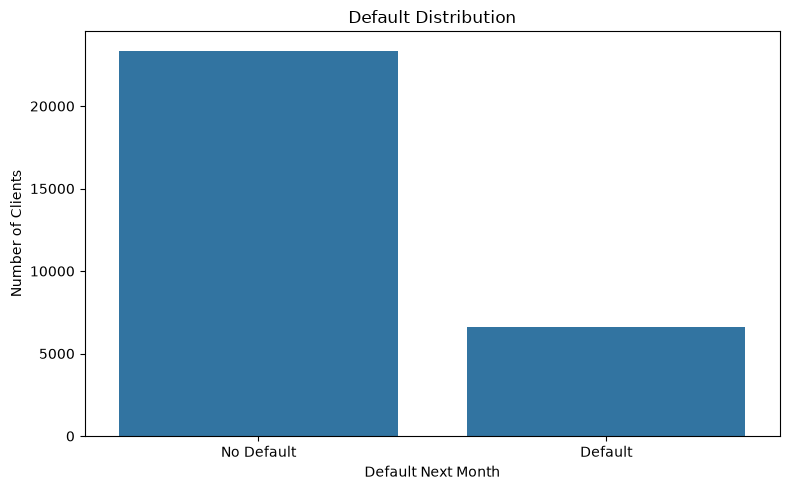

In [40]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="DEFAULT"
)

plt.title("Default Distribution")
plt.xlabel("Default Next Month")
plt.ylabel("Number of Clients")

plt.xticks(
    [0, 1],
    ["No Default", "Default"]
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "01_initial_default_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [41]:
assert not df.empty
assert "DEFAULT" in df.columns
assert df["DEFAULT"].isin([0, 1]).all()
assert df.columns.is_unique

expected_features = 23

assert len(X.columns) == expected_features, (
    f"Expected {expected_features} features, "
    f"received {len(X.columns)}"
)

print("Basic validation: PASSED")

Basic validation: PASSED


In [42]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 35


In [43]:
raw_file = RAW_PATH / "credit_card_default.csv"

df.to_csv(
    raw_file,
    index=False
)

print("Dataset saved:", raw_file)

Dataset saved: c:\GITHUB\analytics_platform\data\raw\credit_card_default.csv
